# Week 11 · Lecture 1
## From consumption Euler equations to Lucas tree prices

**Required reading:** [QuantEcon, Asset Pricing: Finite State Models](https://python.quantecon.org/markov_asset.html).  
**Prerequisites:** Markov chains, conditional expectation, Bellman equations, Euler equations, and matrix algebra.  
**Learning objectives:** derive the stochastic discount factor (SDF); price a Lucas tree in a finite-state economy; solve prices both as a linear system and by iteration; explain the log-utility benchmark.

**Roadmap (75 minutes):** 10 min Euler equation review; 15 min risky claims; 10 min Markov states; 15 min Lucas tree; 15 min linear algebra and iteration; 10 min log utility.

This notebook uses the **same illustrative three-state economy as the Week 11 problem set**. It is not a replication of QuantEcon's calibrated examples.

## 1. From household optimization to a risky-asset Euler equation

Consider an investor who chooses consumption and holdings $\theta_{t+1}$ of an asset. Buying one unit today costs $p_t$ units of consumption and yields $p_{t+1}+d_{t+1}$ next period. A small increase $\varepsilon$ in holdings changes current consumption by $-p_t\varepsilon$ and next-period consumption by $(p_{t+1}+d_{t+1})\varepsilon$.

At an **interior** optimum, the derivative of expected lifetime utility with respect to $\varepsilon$ vanishes:

$$-u'(c_t)p_t+\beta\mathbb E_t\left[u'(c_{t+1})(p_{t+1}+d_{t+1})\right]=0.$$

Hence

$$\boxed{p_t=\mathbb E_t\left[m_{t+1}(p_{t+1}+d_{t+1})\right]},\qquad
m_{t+1}=\beta\frac{u'(c_{t+1})}{u'(c_t)}.$$

The **SDF** measures the marginal-utility value today of a unit of consumption delivered tomorrow. This is the risky-asset counterpart of the deterministic Euler equation $u'(c_t)=\beta R u'(c_{t+1})$.

**Discussion:** Why does an asset paying especially well in bad consumption states tend to be valuable?

## 2. A finite-state growth economy

Let $s_t\in\{0,1,2\}$ denote the **current growth state**, and suppose the next-period dividend/consumption growth factor is $g_{s_{t+1}}$:

$$\frac{d_{t+1}}{d_t}=\frac{c_{t+1}}{c_t}=g_{s_{t+1}}.$$

Conditional on $s_t=i$, the next state $j$ occurs with probability $P_{ij}$. Thus $\mathbb E_t[f(s_{t+1})]=\sum_jP_{ij}f(j)$. Our illustrative state labels are recession, normal, and expansion.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

states = ["Recession", "Normal", "Expansion"]
P = np.array([[0.80, 0.15, 0.05],
              [0.10, 0.80, 0.10],
              [0.05, 0.15, 0.80]])
g = np.array([0.98, 1.02, 1.06])
beta, gamma = 0.95, 2.0
assert np.allclose(P.sum(axis=1), 1)
print("Transition matrix:", P)
print("Growth factors:", dict(zip(states, g)))

Transition matrix: [[0.8  0.15 0.05]
 [0.1  0.8  0.1 ]
 [0.05 0.15 0.8 ]]
Growth factors: {'Recession': np.float64(0.98), 'Normal': np.float64(1.02), 'Expansion': np.float64(1.06)}


### Stationary distribution and simulated states

A stationary distribution $\pi$ solves $\pi^\top P=\pi^\top$, $\sum_i\pi_i=1$. It describes the long-run fraction of periods spent in each state; it is **not** the probability distribution of next period's state conditional on today's state.

Stationary distribution: {'Recession': np.float64(0.2857), 'Normal': np.float64(0.4286), 'Expansion': np.float64(0.2857)}


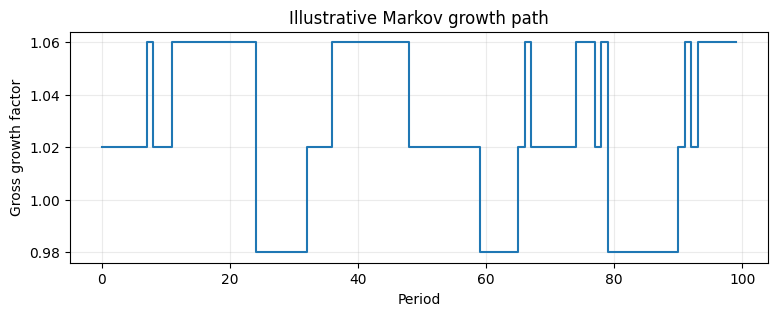

In [2]:
A = P.T - np.eye(len(g))
A[-1, :] = 1
b = np.zeros(len(g)); b[-1] = 1
pi = np.linalg.solve(A, b)
print("Stationary distribution:", dict(zip(states, np.round(pi, 4))))

rng = np.random.default_rng(2026)
T = 100
s = np.zeros(T, dtype=int)
s[0] = 1
for t in range(T-1):
    s[t+1] = rng.choice(len(g), p=P[s[t]])
fig, ax = plt.subplots(figsize=(9, 3))
ax.step(range(T), g[s], where='post')
ax.set(xlabel='Period', ylabel='Gross growth factor', title='Illustrative Markov growth path')
ax.grid(alpha=.25)
plt.show()

## 3. Lucas tree equilibrium and CRRA preferences

A Lucas tree is a claim to the aggregate endowment $d_t$. In equilibrium $c_t=d_t$. Assume $u'(c)=c^{-\gamma}$, including the logarithmic case $\gamma=1$.

The SDF in the transition $i\to j$ is

$$m_{ij}=\beta g_j^{-\gamma}.$$

Conjecture that the ex-dividend tree price takes the form $p_t=v_{s_t}d_t$. Substituting into the asset-pricing Euler equation gives

$$v_i d_t=\sum_jP_{ij}\beta g_j^{-\gamma}\big(v_jd_{t+1}+d_{t+1}\big).$$

Since $d_{t+1}=g_jd_t$ in next state $j$,

$$\boxed{v_i=\beta\sum_jP_{ij}g_j^{1-\gamma}(1+v_j).}$$

**Important:** The exponent is $1-\gamma$, not $-\gamma$: the payoff itself grows by $g_j$.

## 4. A linear system replaces an infinite-horizon problem

Define $J_{ij}=P_{ij}g_j^{1-\gamma}$ and $\mathbf 1=(1,1,1)^\top$. Then

$$v=\beta J(\mathbf 1+v),\qquad (I-\beta J)v=\beta J\mathbf 1.$$

If the spectral radius $\rho(\beta J)<1$, the finite, no-bubble solution is

$$\boxed{v=(I-\beta J)^{-1}\beta J\mathbf 1.}$$

In code, use `np.linalg.solve` rather than explicitly computing a matrix inverse.

In [3]:
def lucas_pd(P, g, beta, gamma):
    J = P * g[np.newaxis, :]**(1-gamma)
    B = beta * J
    radius = max(abs(np.linalg.eigvals(B)))
    if radius >= 1:
        raise ValueError("Finite fundamental P/D ratio is not guaranteed: spectral radius >= 1")
    v = np.linalg.solve(np.eye(len(g)) - B, B @ np.ones(len(g)))
    return v, B, radius

v, B, radius = lucas_pd(P, g, beta, gamma)
for name, price in zip(states, v):
    print(f"{name:10s}: P/D = {price:.6f}")
print(f"Spectral radius = {radius:.6f}")
print("Maximum pricing-equation residual:", np.max(np.abs(v - B @ (1+v))))

Recession : P/D = 15.619119
Normal    : P/D = 14.108506
Expansion : P/D = 12.837472
Spectral radius = 0.934648
Maximum pricing-equation residual: 0.0


## 5. Successive approximation and the link to dynamic programming

Starting at $v^{(0)}=0$, repeatedly apply the pricing operator

$$\mathcal T(v)=\beta J(\mathbf 1+v).$$

Then $v^{(k+1)}=\mathcal T(v^{(k)})$. Under $\rho(\beta J)<1$, this iteration converges to the fundamental price-dividend vector. Each additional iteration incorporates a longer horizon of future dividends. Unlike the Bellman operator for an optimal-control problem, this pricing operator is **linear-affine**: there is no maximization.

Iterations: 382 max error: 9.737810557908233e-11


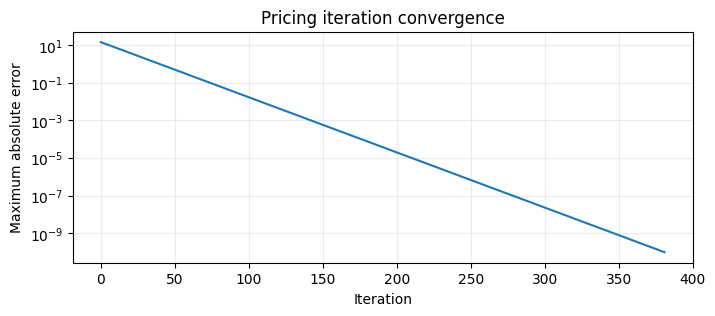

In [4]:
v_iter = np.zeros(len(g))
errors = []
for k in range(600):
    v_iter = B @ (np.ones(len(g)) + v_iter)
    errors.append(np.max(np.abs(v_iter-v)))
    if errors[-1] < 1e-10:
        break
print("Iterations:", k+1, "max error:", errors[-1])
fig, ax = plt.subplots(figsize=(8,3))
ax.semilogy(np.maximum(errors, 1e-16))
ax.set(xlabel='Iteration', ylabel='Maximum absolute error', title='Pricing iteration convergence')
ax.grid(alpha=.25)
plt.show()

## 6. The log-utility benchmark

When $\gamma=1$, $J_{ij}=P_{ij}$ because $g_j^{1-\gamma}=1$. Hence

$$v=\beta P(\mathbf 1+v).$$

A constant solution $v_i=\bar v$ satisfies $\bar v=\beta(1+\bar v)$, since each row of $P$ sums to one. Thus

$$\boxed{v_i=\frac{\beta}{1-\beta}=19\quad\text{for all states}.}$$

**Interpretation:** With log utility and a tree that pays aggregate consumption, the growth in the payoff exactly offsets the marginal-utility adjustment. This does **not** mean that all assets have state-independent prices.

In [5]:
v_log, _, _ = lucas_pd(P, g, beta, gamma=1.0)
print("Log-utility P/D ratios:", v_log)
assert np.allclose(v_log, beta/(1-beta))

for risk_aversion in [0, 1, 2, 4]:
    prices, _, _ = lucas_pd(P, g, beta, risk_aversion)
    print(f"gamma={risk_aversion}: {np.round(prices, 4)}")

Log-utility P/D ratios: [19. 19. 19.]
gamma=0: [30.2715 33.6699 37.5543]
gamma=1: [19. 19. 19.]
gamma=2: [15.6191 14.1085 12.8375]
gamma=4: [14.0593 10.4379  8.1075]


## 7. Wrap-up and quick checks

1. In the transition $i\to j$, why is the SDF $\beta g_j^{-\gamma}$ but the Lucas tree matrix contains $g_j^{1-\gamma}$?
2. Why does the matrix inverse represent an infinite sequence of discounted expected dividends?
3. Explain why log utility yields a constant tree price-dividend ratio, even when dividend growth is persistent.
4. What does the condition $\rho(\beta J)<1$ rule out?

**Connection to the problem set:** Problems 1–3 and the log-utility portion of Problem 6.  
**Next lecture:** Risk aversion, state persistence, one-period risk-free claims, and consol bonds.